# 02. Churn modeling

Guideline steps 5-8: stratified split, Logistic Regression baseline, comparison with Random Forest, XGBoost and LightGBM, then precision, recall and F1 (plus ROC-AUC, PR-AUC and Brier score), feature importance, calibration, and the cost-based threshold.

In [1]:
import sys
sys.path.insert(0, '../python')          # reusable code lives in /python
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from data_preprocessing import get_clean_data
from model_training import train_and_compare
from model_evaluation import evaluate, RETENTION_COST, SAVE_RATE
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 1. Stratified train/test split

In [2]:
_, df = get_clean_data()
res = train_and_compare(df)
ytr, yte = res['ytr'], res['yte']
pd.DataFrame({'Customers': [len(ytr), len(yte)], 'Churn rate %': [ytr.mean()*100, yte.mean()*100]}, index=['Train (75%)', 'Test (25%)']).round(1)

,Customers,Churn rate %
Train (75%),2137,15.6
Test (25%),713,15.7


## 2. Model comparison (default threshold 0.5, test set)

Only 15.6% of customers churn, so accuracy alone is misleading (predicting 'nobody leaves' is already 84% accurate). Models use class weights, and selection is based on PR-AUC and F1.

In [3]:
mc = res['comparison']
print('Selected model:', res['best'])
mc

Selected model: LightGBM


,Model,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier_Raw,Brier_Calibrated,TP,FP,FN,TN,Selected
0,Logistic Regression (baseline),0.5128,0.8929,0.6515,0.9335,0.7755,0.1078,0.0668,100,95,12,506,No
1,Random Forest,0.7500,0.9107,0.8226,0.9794,0.9071,0.0465,0.0353,102,34,10,567,No
2,XGBoost,0.7222,0.9286,0.8125,0.9796,0.9197,0.0480,0.0366,104,40,8,561,No
3,LightGBM,0.7556,0.9107,0.8259,0.9782,0.9260,0.0424,0.0348,102,33,10,568,Yes


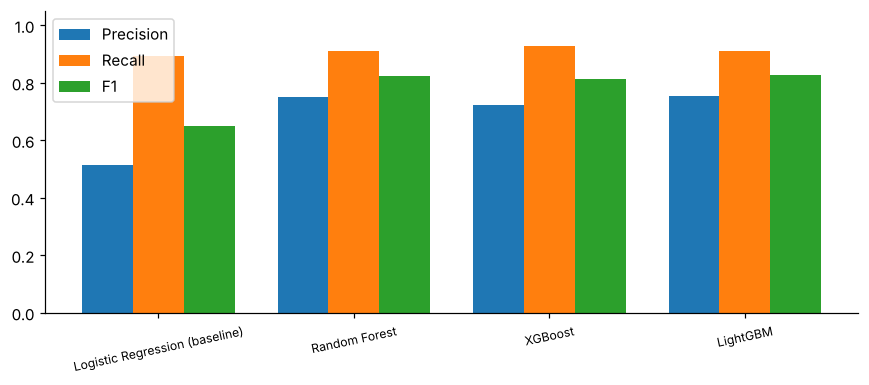

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(mc)); w = 0.26
for k, m in enumerate(['Precision', 'Recall', 'F1']):
    ax.bar(x + (k-1)*w, mc[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(mc.Model, rotation=12, fontsize=8); ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

LightGBM has the best PR-AUC (0.926) with a strong F1 (0.8259). The baseline finds most churners but raises many more false alarms (95 against 33).

## 3. Confusion matrices at the default threshold

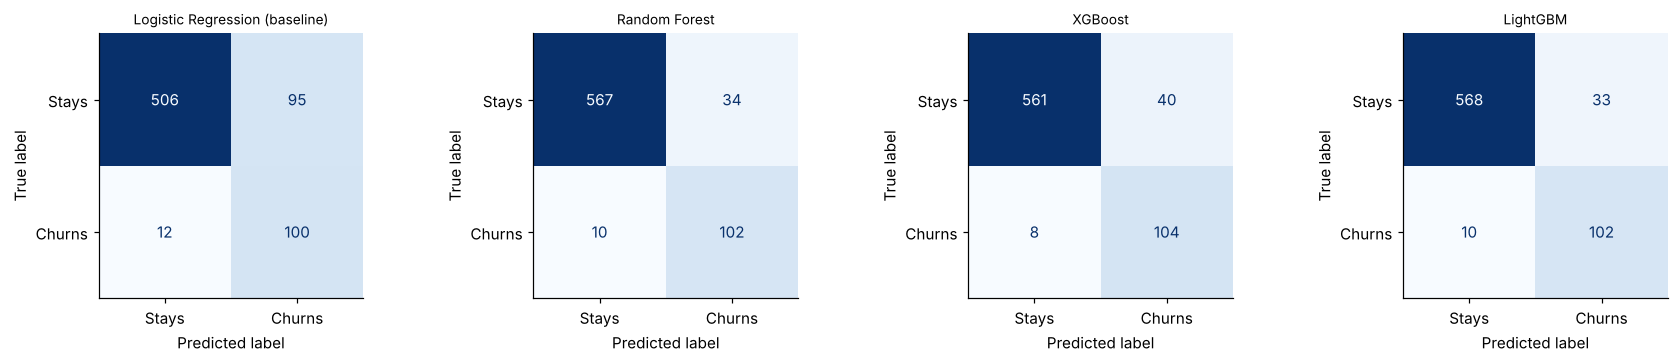

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (name, (cm, pc)) in zip(axes, res['cal'].items()):
    p = res['models'][name].predict_proba(res['Xte'])[:, 1]
    ConfusionMatrixDisplay(confusion_matrix(yte, (p >= 0.5).astype(int)), display_labels=['Stays', 'Churns']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

## 4. Evaluation of the selected model

Cost-based threshold, calibration and feature importance.

In [6]:
ev = evaluate(res)
print('Cost-optimal threshold:', ev['threshold'])
ev['confusion']

Cost-optimal threshold: 0.1


{'TN': 545, 'FP': 56, 'FN': 3, 'TP': 109}

### Feature importance (permutation, average precision)

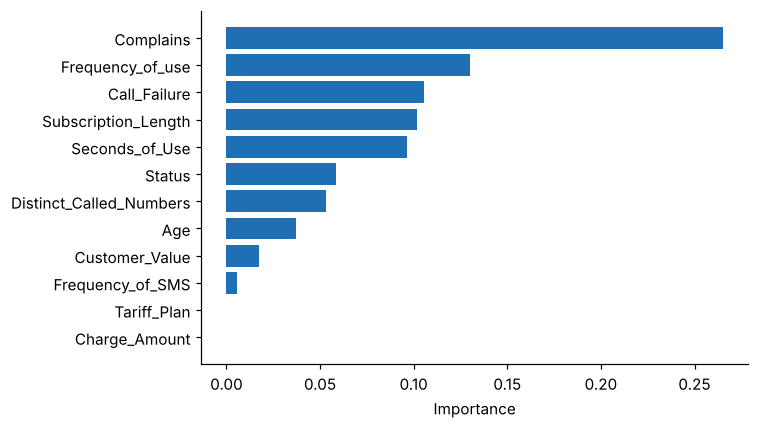

In [7]:
fi = ev['importance'].sort_values('Importance')
plt.figure(figsize=(7, 4)); plt.barh(fi.Feature, fi.Importance, color='#1F6FB5'); plt.xlabel('Importance'); plt.tight_layout(); plt.show()

### Calibration: can the probabilities be trusted?

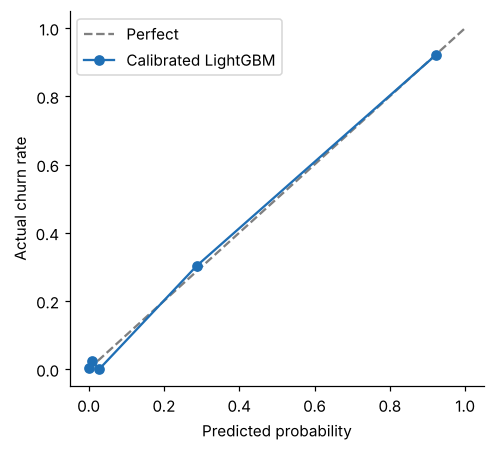

,Predicted_Probability,Actual_Churn_Rate
0,0.0000,0.0027
1,0.0084,0.0241
2,0.0280,0.0000
3,0.2874,0.3034
4,0.9223,0.9213


In [8]:
cal = ev['calibration']
plt.figure(figsize=(4.6, 4.2)); plt.plot([0, 1], [0, 1], '--', color='grey', label='Perfect')
plt.plot(cal.Predicted_Probability, cal.Actual_Churn_Rate, 'o-', color='#1F6FB5', label='Calibrated LightGBM')
plt.xlabel('Predicted probability'); plt.ylabel('Actual churn rate'); plt.legend(); plt.tight_layout(); plt.show()
cal

### Cost-based threshold

A false positive costs the retention offer (20); a false negative costs the customer's value. Total cost = 20 x customers contacted + value of the churners missed.

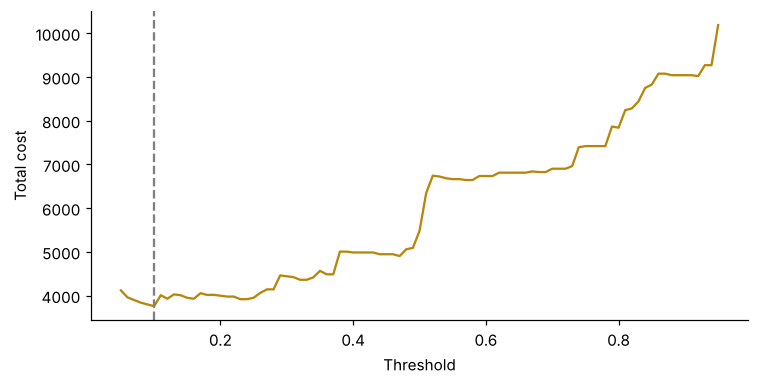

,Threshold,Contacted,TP,FP,FN,Total_Cost,Recommended
0,0.05,183,109,74,3,4116.680,No
5,0.10,165,109,56,3,3756.680,Yes
15,0.20,143,105,38,7,3996.270,No
25,0.30,129,99,30,13,4440.510,No
35,0.40,113,94,19,18,4984.725,No
45,0.50,101,89,12,23,5479.575,No
65,0.70,87,80,7,32,6901.215,No
85,0.90,59,58,1,54,9040.655,No
90,0.95,54,54,0,58,10187.525,No


In [9]:
tc = ev['threshold_cost']
plt.figure(figsize=(7, 3.6)); plt.plot(tc.Threshold, tc.Total_Cost, color='#B8860B')
plt.axvline(ev['threshold'], ls='--', color='grey'); plt.xlabel('Threshold'); plt.ylabel('Total cost'); plt.tight_layout(); plt.show()
tc[tc.Threshold.isin([0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.70, 0.90, 0.95])][['Threshold','Contacted','TP','FP','FN','Total_Cost','Recommended']]

At the cost-optimal threshold of 0.10 the model catches 109 of the 112 real churners (recall 97%) with 56 false alarms. These counts differ from the comparison table above because that table uses raw scores at the default threshold of 0.5, while this matrix uses calibrated probabilities at the cost-optimal threshold.